File created for Data Science Challenge - Artefact

In [30]:
#import dependencies

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pickle

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
) 

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve,
    precision_score,
    recall_score,
    classification_report,
    f1_score
)


Lists of features used during the project   

In [38]:
initial_features = ['datahora_transacao',
'nome_estabelecimento',
'tipo_estabelecimento',
'valor_transacao',
'nome_cliente',
'cidade',
'flag_fraude',
'device_type',
'is_new_device',
'temperatura_celsius',
'codigo_postal',
'score_interno',
'turno',
'valor_categoria',
'cidade_regiao]']

model_features = ['is_new_device',
'is_weekend',
'changed_cidade',
'changed_tipo_estabelecimento',
'changed_device_type',
'changed_turno',
'changed_valor_categoria',
'month',
'fraudes_ultimos_30d',
'tipo_estabelecimento_E-commerce',
'tipo_estabelecimento_Food & Beverage',
'tipo_estabelecimento_Fuel',
'tipo_estabelecimento_Pharmacy',
'tipo_estabelecimento_Retail',
'tipo_estabelecimento_Supermarket',
'cidade_Belo Horizonte',
'cidade_Curitiba',
'cidade_Porto Alegre',
'cidade_Recife',
'cidade_Rio de Janeiro',
'cidade_Salvador',
'cidade_São Paulo',
'device_type_desktop',
'device_type_mobile',
'device_type_tablet',
'turno_madrugada',
'turno_manha',
'turno_noite',
'turno_tarde',
'valor_categoria_alto',
'valor_categoria_baixo',
'valor_categoria_medio',
]

## Exploratory Data Analisys

In [2]:
# At this moment, we will load the data and check the first few rows to understand its structure.
# ---------------------------------------------------------
df_historical = pd.read_csv('transacoes_historico_2025.csv')
df_historical.head()

,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,valor_transacao,nome_cliente,cidade,flag_fraude,device_type,is_new_device,temperatura_celsius,codigo_postal,score_interno,turno,valor_categoria,cidade_regiao
0,2025-01-01 00:00:00,Pharmacy Z,Pharmacy,9.12,Cliente_16621,Recife,False,desktop,False,31.5,72519-282,562,madrugada,baixo,Nordeste
1,2025-01-01 00:01:00,Supermarket A,Supermarket,37.74,Cliente_12596,Recife,False,mobile,False,28.1,43549-179,461,madrugada,medio,Nordeste
2,2025-01-01 00:02:00,Restaurant Y,Food & Beverage,30.94,Cliente_10474,Salvador,False,mobile,True,29.1,68582-277,577,madrugada,medio,Nordeste
3,2025-01-01 00:03:00,Gas Station,Fuel,41.72,Cliente_20661,Salvador,False,mobile,True,28.6,21497-208,666,madrugada,medio,Nordeste
4,2025-01-01 00:04:00,Online Shop 2,E-commerce,13.85,Cliente_4018,Rio de Janeiro,False,mobile,False,30.2,50814-648,892,madrugada,baixo,Sudeste


### Main informations and First Steps

In [3]:
# Number of rows and columns in the dataset
# ---------------------------------------------------------
print("transacoes_historico_2025.csv has", df_historical.shape[0], "rows and", df_historical.shape[1], "columns")

# Number of Missing Values in each column
# ---------------------------------------------------------
missing_values = df_historical.isnull().sum()
print("\nMissing Values in each column:")
print(missing_values)

# Datatypes of each column
# ---------------------------------------------------------
print("\nDatatypes of each column:")
for column in df_historical.columns:
    print(f"{column}: {df_historical[column].dtype}")

transacoes_historico_2025.csv has 523525 rows and 15 columns

Missing Values in each column:
datahora_transacao      0
nome_estabelecimento    0
tipo_estabelecimento    0
valor_transacao         0
nome_cliente            0
cidade                  0
flag_fraude             0
device_type             0
is_new_device           0
temperatura_celsius     0
codigo_postal           0
score_interno           0
turno                   0
valor_categoria         0
cidade_regiao           0
dtype: int64

Datatypes of each column:
datahora_transacao: object
nome_estabelecimento: object
tipo_estabelecimento: object
valor_transacao: float64
nome_cliente: object
cidade: object
flag_fraude: bool
device_type: object
is_new_device: bool
temperatura_celsius: float64
codigo_postal: object
score_interno: int64
turno: object
valor_categoria: object
cidade_regiao: object


Analizing these results we can observe that thankfully, there are no missing values in the dataset. Additionally, the columns have correct types according on their meaning. The only exception is "datahora_transacao" column that might be timestamp.

In [5]:
# Converting the column "datahora_transacao" to datetime format
# ---------------------------------------------------------
df_historical['datahora_transacao'] = pd.to_datetime(df_historical['datahora_transacao'], format='%Y-%m-%d %H:%M:%S')

# Evaluating the conversion
# ---------------------------------------------------------
print("\nDatatypes of \"datahora_transacao\" column after conversion:" + str(df_historical["datahora_transacao"].dtype))

print("Number of non-null values in \"datahora_transacao\" column after conversion:", df_historical["datahora_transacao"].notnull().sum())

# The conversion was successful, and the number of non-null values in the "datahora_transacao" column remains the same!


Datatypes of "datahora_transacao" column after conversion:datetime64[ns]
Number of non-null values in "datahora_transacao" column after conversion: 523525


In [6]:
# Number of fraud events in the dataset
# ---------------------------------------------------------
num_fraud_events = df_historical['flag_fraude'].sum()
print("\nNumber of fraud events in the dataset:", num_fraud_events)


Number of fraud events in the dataset: 20485


This number represents 20485/523525 = 3.91% of the dataset, which indicates that it is an imbalanced dataset. Therefore, it is necessary to take some additional steps to build the model.

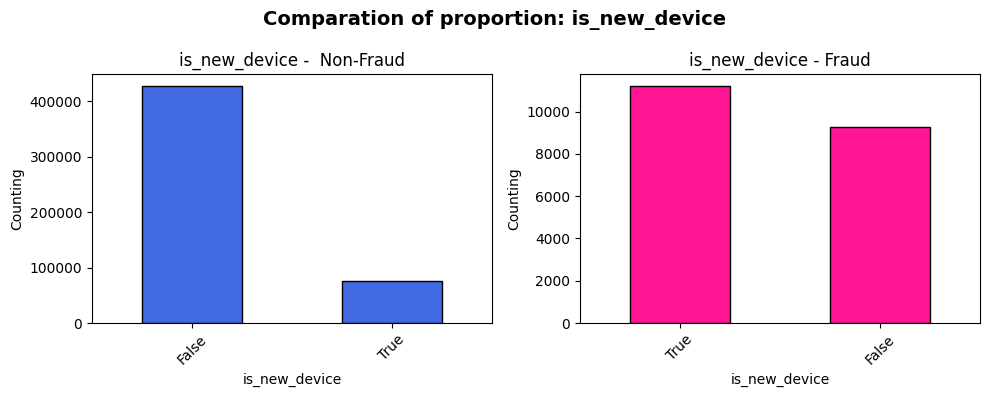

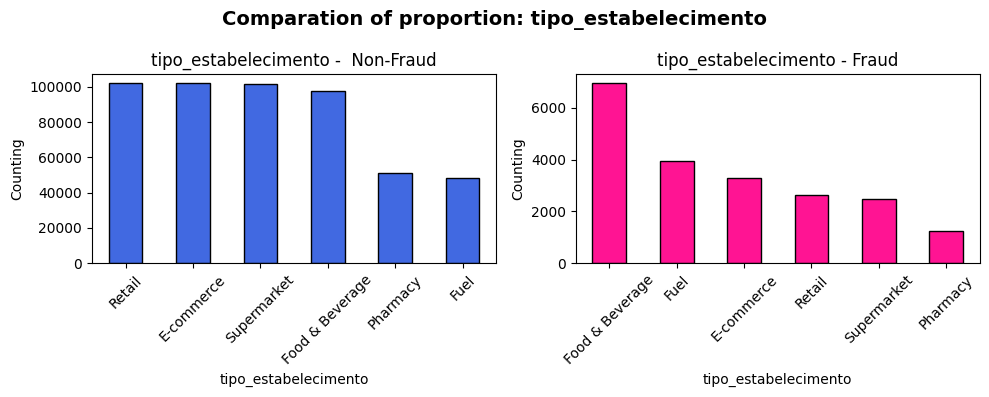

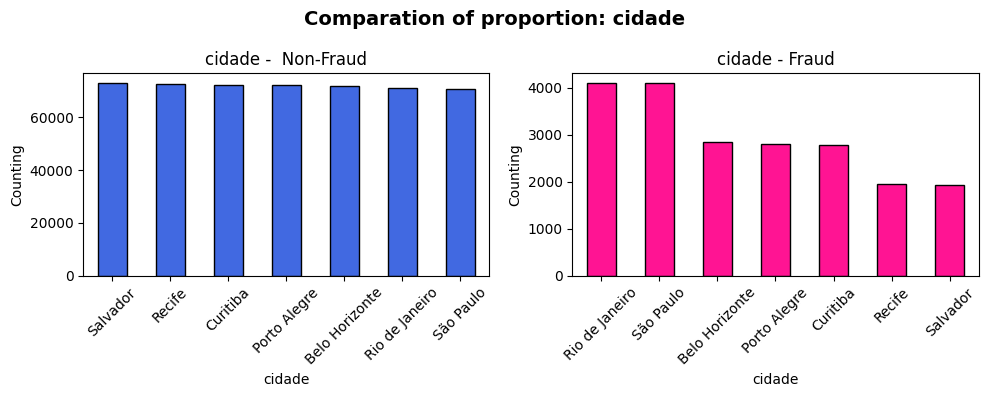

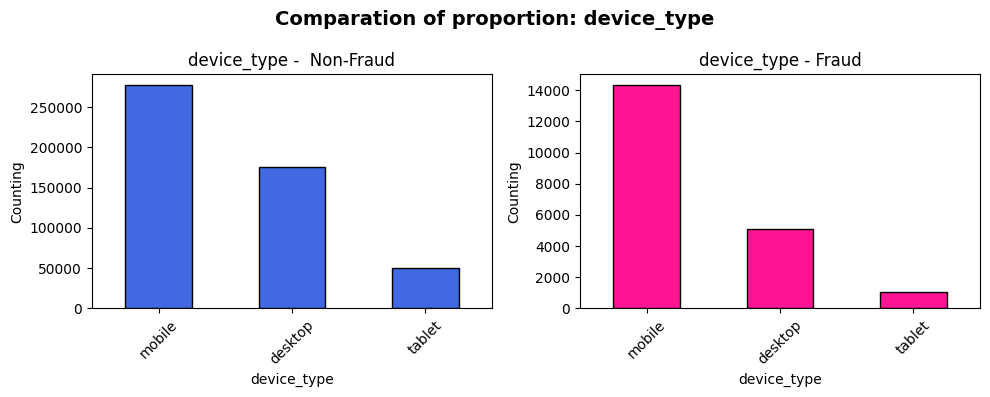

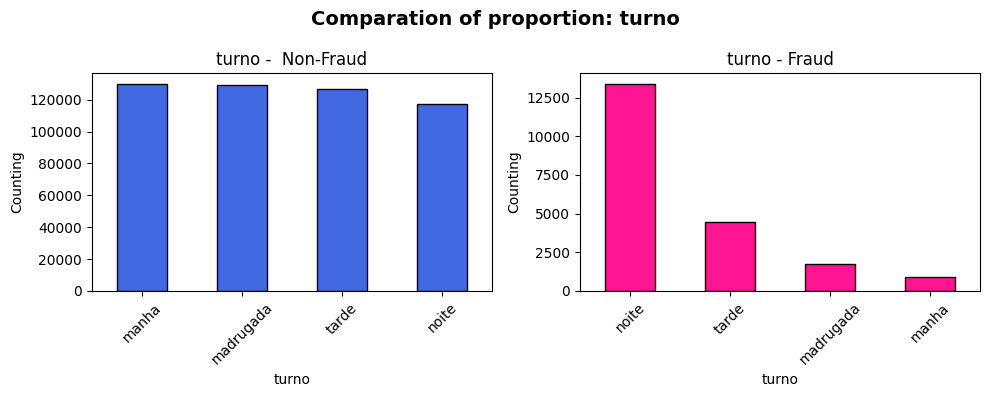

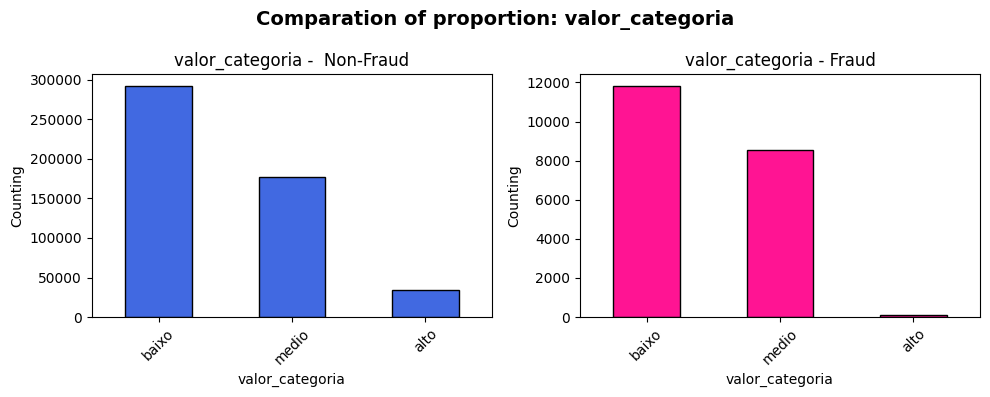

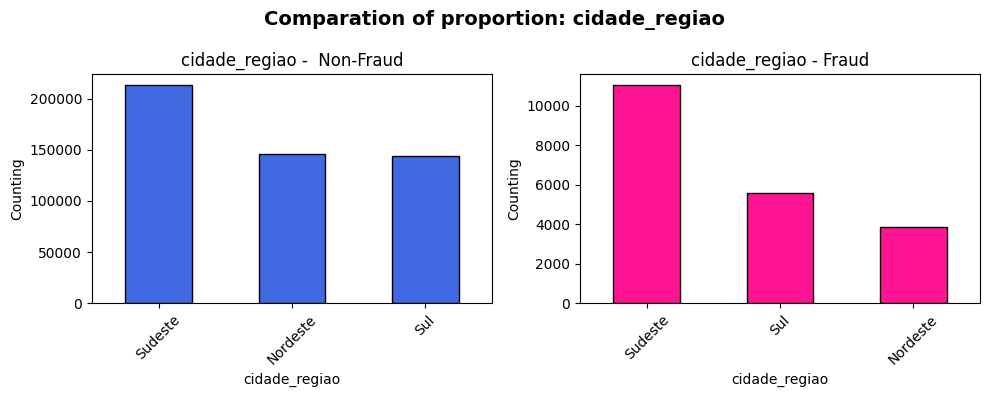

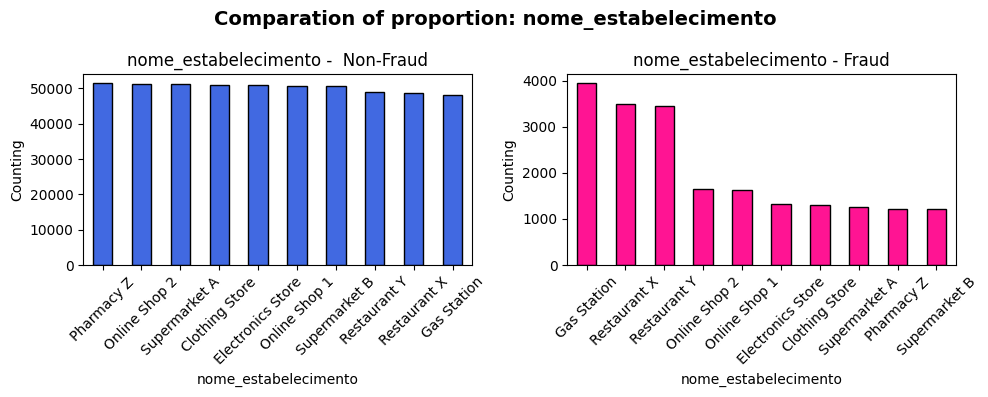

In [7]:
# Plotting the barcharts for categorical columns 
# ---------------------------------------------------------

categorical_columns = [
    'is_new_device', 'tipo_estabelecimento', 'cidade', 
    'device_type', 'turno', 'valor_categoria', 'cidade_regiao', 'nome_estabelecimento'
]

for col in categorical_columns:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    
    df_historical[df_historical['flag_fraude'] == 0][col].value_counts().plot(
        kind='bar', ax=axes[0], color='royalblue', edgecolor='black'
    )
    axes[0].set_title(f'{col} -  Non-Fraud')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Counting')
    axes[0].tick_params(axis='x', rotation=45)
    
    df_historical[df_historical['flag_fraude'] == 1][col].value_counts().plot(
        kind='bar', ax=axes[1], color='deeppink', edgecolor='black'
    )
    axes[1].set_title(f'{col} - Fraud')
    axes[1].set_xlabel(col)
    axes[1].set_ylabel('Counting') 
    axes[1].tick_params(axis='x', rotation=45)
    
    plt.suptitle(f'Comparation of proportion: {col}', fontsize=14, fontweight='bold')
    
    plt.tight_layout()
    plt.show()

The bar charts clearly show the difference in scale between the data labeled as “Fraud” and “Non-Fraud.” Some features have the same data distribution, such as “categoria_valor”, “device_type”, and “cidade_regiao”. 

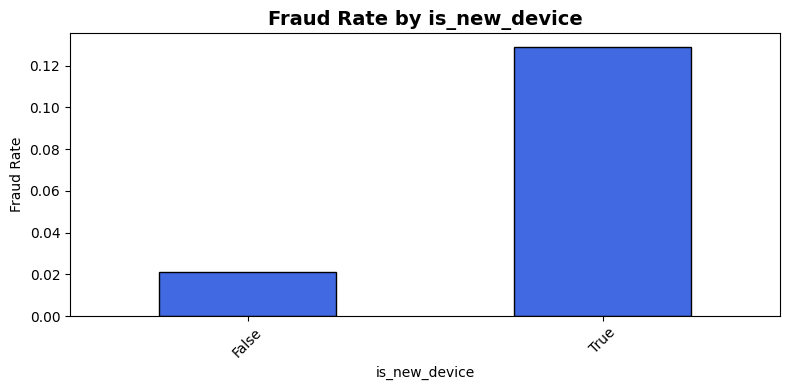

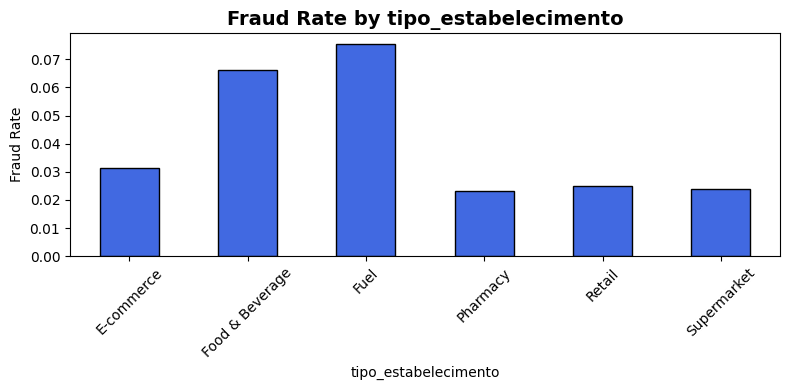

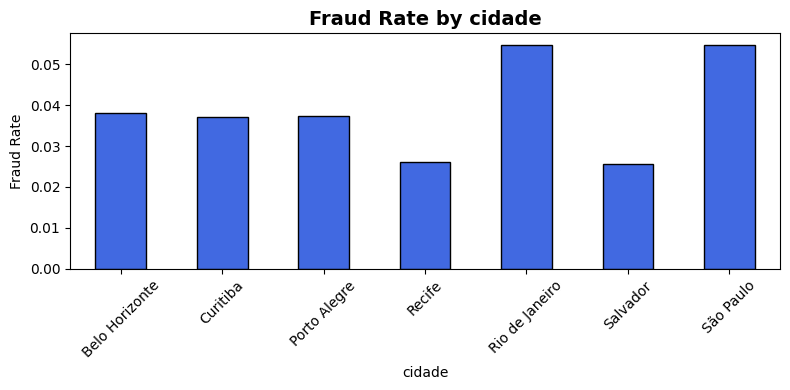

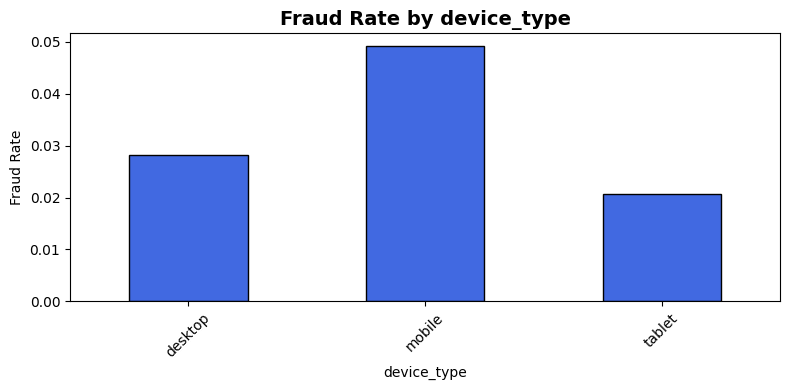

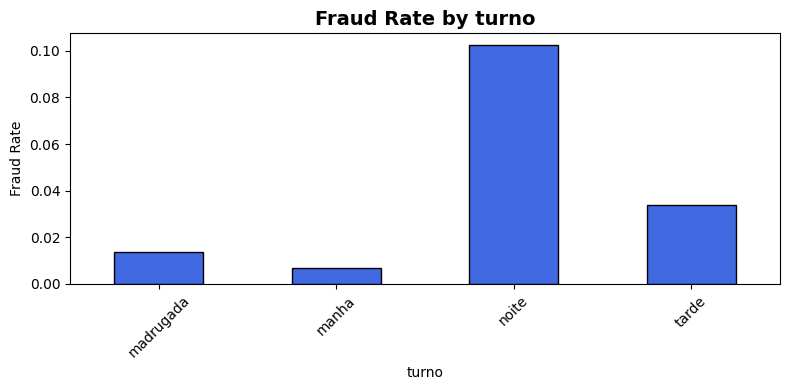

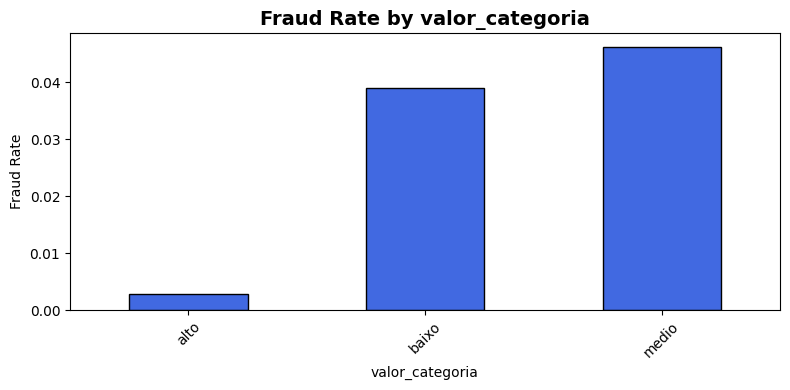

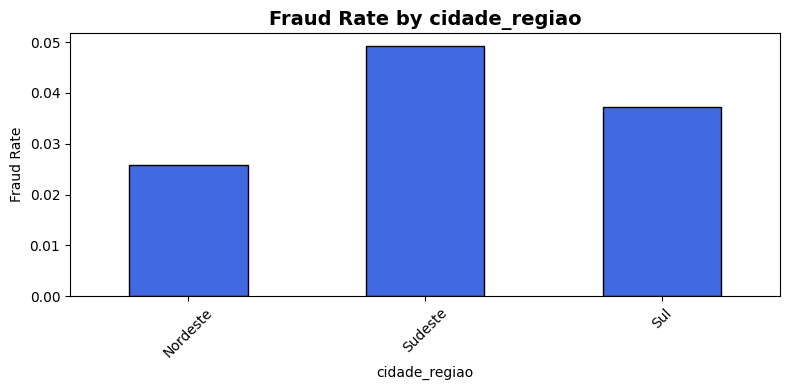

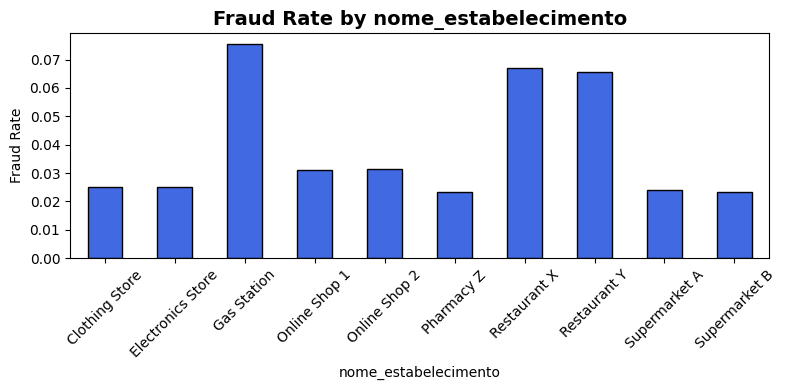

In [8]:
# plotting the fraud rate for each categorical column
# ---------------------------------------------------------

for col in categorical_columns:
    fraud_rate = df_historical.groupby(col)['flag_fraude'].mean()
    
    plt.figure(figsize=(8, 4))
    fraud_rate.plot(kind='bar', color='royalblue', edgecolor='black')
    plt.title(f'Fraud Rate by {col}', fontsize=14, fontweight='bold')
    plt.xlabel(col)
    plt.ylabel('Fraud Rate')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Looking at the bar charts showing the fraud transaction rate, we can conclude that all features have labels associated with higher fraud rates. This can be observed, for example, in the cities of Rio de Janeiro and São Paulo under the “cidade” feature, “Mobile” under the “device_type” feature, “night” under the ‘turno’ feature, and “Gas Station,” “Restaurant X,” and “Restaurant Y” under the “nome_estabelecimento” feature. Therefore, using these features for training will help improve the model.

### Temporal and numerical analisys

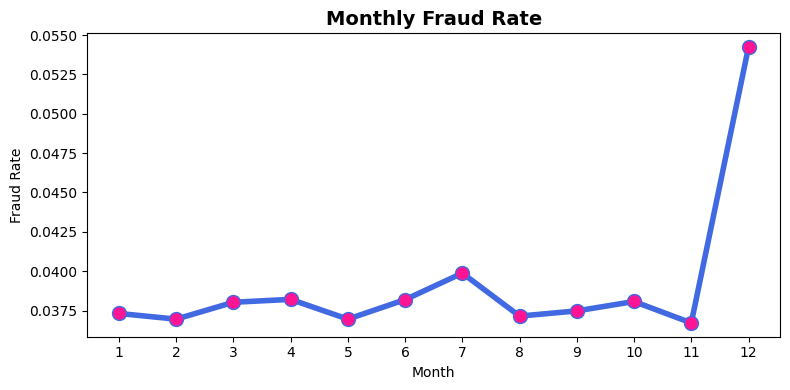

In [9]:
# Preparing dataset for monthly analysis
# ---------------------------------------------------------
df_historical['month'] = df_historical['datahora_transacao'].dt.month
monthly = df_historical.groupby('month')['flag_fraude'].agg(['mean', 'sum', 'count'])
monthly = monthly.rename(columns={'mean': 'fraud_rate', 'sum': 'qtd_fraud', 'count': 'qtd_total'})

plt.figure(figsize=(8, 4))
plt.plot(monthly.index, monthly['fraud_rate'], marker='o', color='royalblue', linestyle='-', linewidth=4, markersize=10, markerfacecolor='deeppink')
plt.title('Monthly Fraud Rate', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Fraud Rate')
plt.xticks(monthly.index)
plt.tight_layout()
plt.show()

By extracting the numerical month from the “datahora_transacao” feature and calculating the fraud rate, it is possible to observe certain seasonal patterns. In months considered “holiday months” (July, December), the number of fraud cases is higher.  

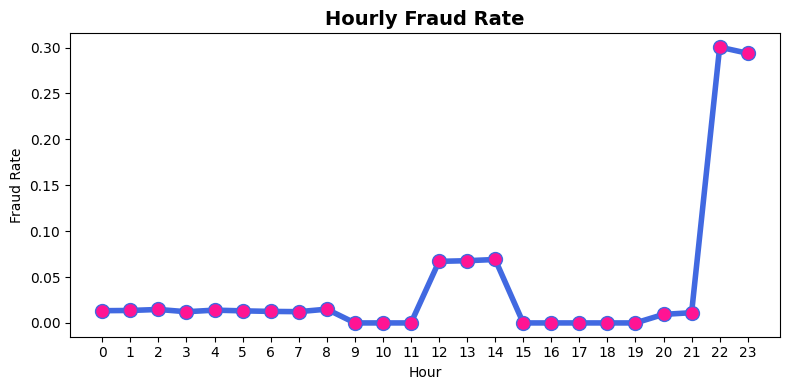

In [10]:
# Preparing dataset for hourly analysis
# ---------------------------------------------------------
df_historical['hour'] = df_historical['datahora_transacao'].dt.hour
hourly = df_historical.groupby('hour')['flag_fraude'].agg(['mean', 'sum', 'count'])
hourly = hourly.rename(columns={'mean': 'fraud_rate', 'sum': 'qtd_fraud', 'count': 'qtd_total'})

plt.figure(figsize=(8, 4))
plt.plot(hourly.index, hourly['fraud_rate'], marker='o', color='royalblue', linestyle='-', linewidth=4, markersize=10, markerfacecolor='deeppink')
plt.title('Hourly Fraud Rate', fontsize=14, fontweight='bold')
plt.xlabel('Hour')
plt.ylabel('Fraud Rate')
plt.xticks(hourly.index)
plt.tight_layout()
plt.show()

Seasonal patterns can also be observed in the data broken down by hour of the day. There is a higher rate of fraud during “lunch” hours (12–14) and in the late afternoon.

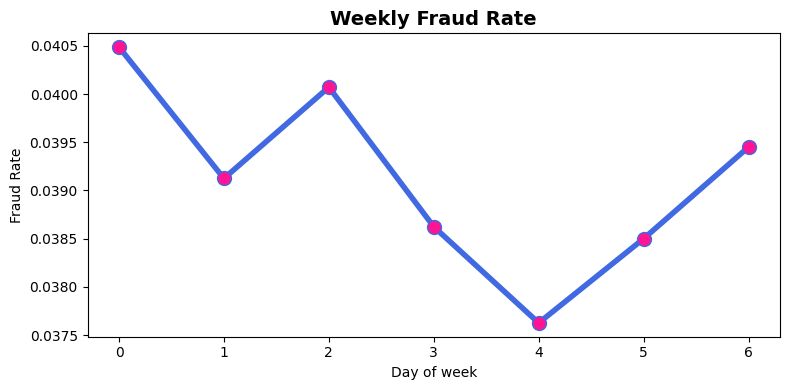

In [11]:
# Preparing dataset for daily analysis (day of the week and day of the month)
# ---------------------------------------------------------
df_historical['day_of_week'] = df_historical['datahora_transacao'].dt.dayofweek

day_of_weekly = df_historical.groupby('day_of_week')['flag_fraude'].agg(['mean','sum','count'])
day_of_weekly = day_of_weekly.rename(columns={'mean': 'fraud_rate', 'sum': 'qtd_fraud', 'count': 'qtd_total'})

plt.figure(figsize=(8,4))
plt.plot(day_of_weekly.index, day_of_weekly['fraud_rate'], marker='o', color='royalblue', linestyle='-', linewidth=4, markersize=10, markerfacecolor='deeppink')
plt.title('Weekly Fraud Rate', fontsize=14, fontweight='bold')
plt.xlabel('Day of week')
plt.ylabel('Fraud Rate')
plt.xticks(day_of_weekly.index)
plt.tight_layout()
plt.show()

When we analyze the fraud rate by day of the week, we see that a lot of fraud occurs on the weekend. Despite this, there isn't a very clear pattern on the other days.

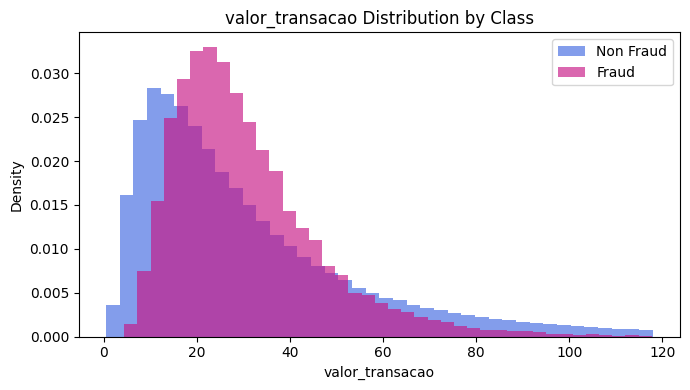

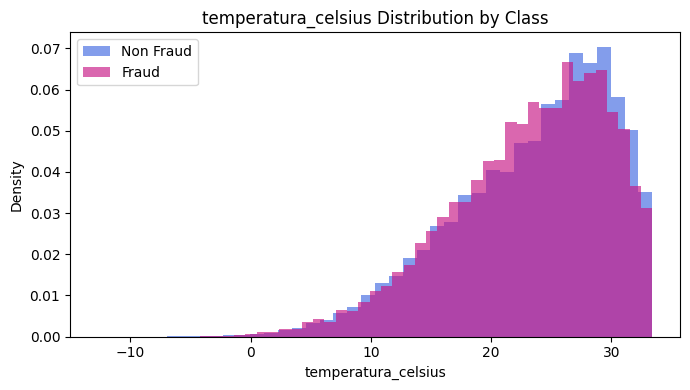

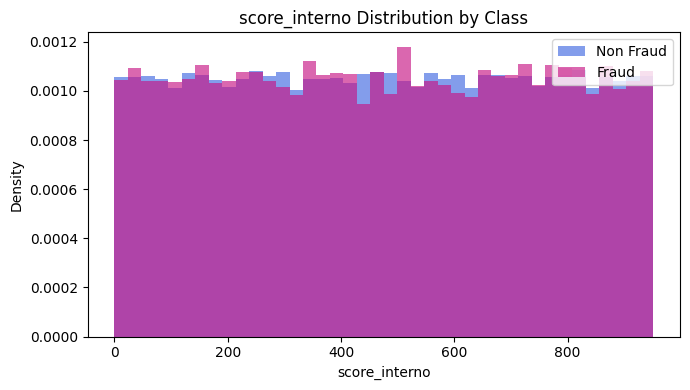

In [12]:
# List of numerical features
# ---------------------------------------------------------
numeric_columns = ['valor_transacao', 'temperatura_celsius', 'score_interno']

for col in numeric_columns:
    plt.figure(figsize=(7, 4))

    upper = df_historical[col].quantile(0.95)
    for target_value, label in [(0, 'Non Fraud'), (1, 'Fraud')]:
        subset = df_historical.loc[(df_historical['flag_fraude'] == target_value) & (df_historical[col] <= upper), col]
        plt.hist(subset, bins=40, alpha=0.65, density=True, label=label, color='royalblue' if target_value == 0 else 'mediumvioletred')
    plt.title(f'{col} Distribution by Class')
    plt.xlabel(col)
    plt.ylabel('Density')
    plt.legend()
    plt.tight_layout()
    plt.show()

For the numerical data, it can be observed that the distributions of the features “temperatura_celsius” and “score_interno” do not show a clear difference between "fraude" and “Não fraude” transactions. This indicates that these features may not help the model learn.

However, for the “valor_transacao” feature, a clear distinction is observed. The average value of fraudulent transactions is higher than that of non-fraudulent transactions. This was also observed when analyzing the “valor_categoria” feature

## Feature Engeneering 

The data will now be reset so that the features can be created and/or transformed. For a clean presentation of results the functions created are in other .py file. 

In [17]:
# Functions used

def transform_dtypes(dataframe: pd.DataFrame, 
                     feature_list: list,
                     making_predictions = True 
    ) -> pd.DataFrame:
    
    """
    Function created to transform dtypes of every feature to assure correct workflow.

    Parameters
    ----------
        dataframe : pd.DataFrame
            Dataframe to have features created.
        
        feature_list : list
            List with initial features list to workflow.

        making_predictions : bool 
            Boolean variable to decide weather the function will be used for predictions or not.
    Returns
        making_predictions : pd.DataFrame
            Dataframe with correct dtypes features
    -------
    """
    # Filtering features according to feature_list
    if making_predictions:
        feature_list_predictions = feature_list
        feature_list_predictions.remove('flag_fraude')

        dataframe = dataframe[feature_list_predictions]
    else:
        dataframe = dataframe[feature_list]

    # Temporal Features
    if 'datahora_transacao' in feature_list:
        dataframe['datahora_transacao'] = pd.to_datetime(dataframe['datahora_transacao'], format='%Y-%m-%d %H:%M:%S')

        return dataframe
    else:
        print(f"Used dataframe has no feature called datahora_transacao")


def create_features(dataframe: pd.DataFrame
    ) -> pd.DataFrame:

    """
    Function for Creating features that will be used in the model training and deploying 

    Parameters
    ----------
        dataframe : pd.DataFrame
            Dataframe to have features created.

    Returns
        dataframe : pd.Dataframe
            Dataframe with new features
    -------
    """

    # Temporal feature "month", "day_of_week", "is_weekend"
    dataframe['month'] = dataframe['datahora_transacao'].dt.month

    dataframe['day_of_week'] = dataframe['datahora_transacao'].dt.dayofweek

    dataframe['is_weekend'] = dataframe['datahora_transacao'].dt.dayofweek >= 5
    ################################################

    # Adding "number of fraudlent transactions of the last month" feature
    dataframe[f'fraudes_ultimos_{30}d'] = 0.0

    for client in dataframe['nome_cliente'].unique():
        
        df_client_temp = (
            dataframe[dataframe['nome_cliente'] == client]
            .sort_values('datahora_transacao')
            .copy()
        )

        fraude_rolling = (
            df_client_temp
            .set_index('datahora_transacao')['flag_fraude']
            .rolling(
                window=f'{30}D',
                closed='left'
            )
            .sum()
            .fillna(0)
            .to_numpy()
        )

        dataframe.loc[
            df_client_temp.index,
            f'fraudes_ultimos_{30}d'
        ] = fraude_rolling
    ################################################

    # Creating feature for "changing current state"
    dataframe["_original_order"] = range(len(dataframe))

    dataframe = dataframe.sort_values(
        ["nome_cliente", "datahora_transacao"]
    )

    well_features = [
        "cidade",
        "tipo_estabelecimento",
        "device_type",
        "turno",
        "valor_categoria"
    ]

    grouped_clients = dataframe.groupby(
        "nome_cliente",
        sort=False,
        dropna=False
    )

    for column in well_features:

        feature_change = f"changed_{column}"

        dataframe[feature_change] = (
            grouped_clients[column]
            .transform(lambda values: values.ne(values.shift()))
            .astype(int)
        )

        first_transaction_indices = (
            grouped_clients
            .head(1)
            .index
        )

        dataframe.loc[
            first_transaction_indices,
            feature_change
        ] = 0

    # Retorna para a ordem original
    dataframe = (
        dataframe
        .sort_values("_original_order")
        .drop(columns="_original_order")
        .reset_index(drop=True)
    )

    return dataframe


def preprocessing_features(
    dataframe: pd.DataFrame,
    numerical_features: list[str],
    categorical_features: list[str],
    scaler = None,
    encoder = None
) -> tuple[pd.DataFrame, StandardScaler, OneHotEncoder]:
    """
    Applies StandardScaler to numerical features and OneHotEncoder
    to categorical features.

    If scaler and encoder are not provided, they are created and fitted.
    Otherwise, the previously fitted objects are only used to transform
    the input data.

    Parameters
    ----------
    dataframe : pd.DataFrame
        Dataframe to be transformed.

    numerical_features : list[str]
        Numerical columns that will be standardized.

    categorical_features : list[str]
        Categorical columns that will be one-hot encoded.

    scaler : StandardScaler, optional
        Previously fitted scaler.

    encoder : OneHotEncoder, optional
        Previously fitted encoder.

    Returns
    -------
    transformed_dataframe : pd.DataFrame
        Dataset after encoding and scaling.

    scaler : StandardScaler
        Fitted scaler.

    encoder : OneHotEncoder
        Fitted encoder.
    """

    dataframe = dataframe.copy()

    # Verify if the features are in the dataframe
    required_features = numerical_features + categorical_features

    missing_features = [
        feature
        for feature in required_features
        if feature not in dataframe.columns
    ]

    if missing_features:
        raise ValueError(
            f"The following columns are not in dataframe: {missing_features}"
        )

    ################################################
    # Standard scaling
    if scaler is None:
        scaler = StandardScaler()

        numerical_values = scaler.fit_transform(
            dataframe[numerical_features]
        )
    else:
        numerical_values = scaler.transform(
            dataframe[numerical_features]
        )

    numerical_dataframe = pd.DataFrame(
        numerical_values,
        columns=numerical_features,
        index=dataframe.index
    )

    ################################################    
    # One-hot encoding
    if encoder is None:
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )

        categorical_values = encoder.fit_transform(
            dataframe[categorical_features]
        )
    else:
        categorical_values = encoder.transform(
            dataframe[categorical_features]
        )

    categorical_columns = encoder.get_feature_names_out(
        categorical_features
    )

    categorical_dataframe = pd.DataFrame(
        categorical_values,
        columns=categorical_columns,
        index=dataframe.index
    )

    ################################################
    # Join transformed features
    remaining_features = dataframe.drop(
        columns=numerical_features + categorical_features
    )

    transformed_dataframe = pd.concat(
        [
            remaining_features,
            numerical_dataframe,
            categorical_dataframe
        ],
        axis=1
    )

    return transformed_dataframe, scaler, encoder

def removing_colunms_for_model(
        dataframe: pd.DataFrame,
        model_feature_list: list,
        making_predictions: bool = True
)-> pd.DataFrame:
    """
    Function created for removing eny unecessary feature.

    Parameters
    ----------
        dataframe : pd.DataFrame
            Dataframe to have features removed.

        model_feature_list : list[str]
            List of features that the model uses for train and prediction

        making_predictions : bool
            Default = True; Boolean variable for defining if the function will be used for training or evaluation.
    Returns
        dataframe : pd.Dataframe
            Dataframe using removed selected features
    -------
    """
    if making_predictions:
        return dataframe[model_feature_list]
    else:
        model_feature_list.append('flag_fraude')
        return dataframe[model_feature_list]


In [18]:
# Load the historical transaction dataset
# ---------------------------------------------------------
df_historical = pd.read_csv("transacoes_historico_2025.csv")

# Load the list of expected input features
# ---------------------------------------------------------
with open("initial_features.txt", "r", encoding="utf-8") as file:
    feature_list = [line.strip() for line in file if line.strip()]

# Convert columns to their expected data types
# ---------------------------------------------------------
df_historical = transform_dtypes(
    df_historical,
    feature_list,
    making_predictions=False
)

# Perform feature engineering
# ---------------------------------------------------------
df_historical = create_features(df_historical)

**FUNCTION** create_features

The `create_features()` function constructs additional features intended to capture temporal patterns, customer behavior, and historical fraud information that may improve the predictive performance of the fraud detection model.

- **Temporal Features**

  Three temporal features are extracted from the transaction timestamp (`datahora_transacao`):

  - `month`: month in which the transaction occurred.
  - `day_of_week`: day of the week (Monday to Sunday).
  - `is_weekend`: binary indicator identifying whether the transaction occurred during a weekend.

- **Historical Fraud Count**

  The feature `fraudes_ultimos_30d` represents the number of fraudulent transactions associated with each customer during the previous 30 days. This feature is computed using a rolling time window for each customer individually, considering only transactions that occurred before the current transaction (`closed='left'`) to avoid data leakage.

- **Behavioral Change Features**

  For each customer, binary indicators are created to identify whether important transaction characteristics changed with respect to the previous transaction. The following attributes are monitored:

  - `cidade`
  - `tipo_estabelecimento`
  - `device_type`
  - `turno`
  - `valor_categoria`

  Each generated feature (`changed_<feature>`) assumes the value:

  - **0** if the attribute remained unchanged (or if it is the customer's first recorded transaction);
  - **1** if the attribute differs from the previous transaction.

  These variables are intended to capture unusual changes in customer behavior that may indicate fraudulent activity.

---
**FUNCTION** preprocessing_features

The `preprocessing_features()` function prepares the engineered dataset for machine learning by applying feature scaling and categorical encoding.

- **Feature Validation**

  Before preprocessing, the function verifies that all specified numerical and categorical features are present in the input dataset. Missing features raise an exception to prevent inconsistent model inputs.

- **Numerical Feature Scaling**

  Numerical variables are standardized using `StandardScaler`, producing features with zero mean and unit variance. During training, the scaler is fitted to the data, while during inference previously fitted parameters are reused to ensure consistency.

- **Categorical Feature Encoding**

  Categorical variables are transformed using `OneHotEncoder`, converting each category into binary indicator variables. The encoder is configured with `handle_unknown="ignore"` so that previously unseen categories can be processed safely during deployment.

- **Dataset Reconstruction**

  Finally, the transformed numerical and categorical features are combined with the remaining variables to produce the final dataset used for model training or prediction. The fitted `StandardScaler` and `OneHotEncoder` objects are also returned, allowing the same preprocessing pipeline to be applied consistently during inference.

In [19]:
# Define numerical and categorical features for preprocessing
# ---------------------------------------------------------
categorical_features = [
    "tipo_estabelecimento",
    "cidade",
    "device_type",
    "turno",
    "valor_categoria",
]

numerical_features = [
    "month",
    "fraudes_ultimos_30d",
]

# Apply feature scaling and categorical encoding
# ---------------------------------------------------------
df_historical, scaler, encoder = preprocessing_features(
    df_historical,
    numerical_features,
    categorical_features,
)

# Load the list of features used by the trained model
# ---------------------------------------------------------
with open("model_features.txt", "r", encoding="utf-8") as file:
    model_feature_list = [
        line.strip()
        for line in file
        if line.strip()
    ]

# Keep only the features required by the model
# ---------------------------------------------------------
df_historical = removing_colunms_for_model(
    df_historical,
    model_feature_list,
    making_predictions=False,
)

In [21]:
# Saving scaler and encoder
# ---------------------------------------------------------

# Save encoder in .plk file
with open('encoder.pkl', 'wb') as file:
    pickle.dump(encoder, file)

# Save encoder in .plk file
with open('scaler.pkl', 'wb') as file:
    pickle.dump(scaler, file)

**FUNCTION** removing_colunms_for_model

- **(`nome_estabelecimento`)**

  The feature `nome_estabelecimento` (merchant name) was removed because it introduces a very large number of unique categories in large-scale datasets, making it unsuitable for machine learning models. Furthermore, the feature `tipo_estabelecimento` already captures the type of service provided, preserving most of the relevant information while significantly reducing the dimensionality of the data.

- **(`valor_transacao`)**

  Both `valor_transacao` and `valor_categoria` describe the monetary value of a transaction. The existence of `valor_categoria` suggests that the company already applies an internal business categorization for transaction amounts. Therefore, only `valor_categoria` was retained, as it reduces the complexity of the input space while naturally mitigating the influence of outliers.

- ** (`cidade`, `codigo_postal`, `cidade_regiao`)**

  The features `cidade`, `codigo_postal`, and `cidade_regiao` contain highly overlapping geographic information. Although the state in which the transaction occurred would likely be the most informative variable, this information is not explicitly available in the dataset. Consequently, `cidade` was retained as the representative geographical feature, while the remaining variables were removed.

- **(`temperatura_celsius`)**

  The feature `temperatura_celsius` has no meaningful relationship with the probability of fraud. Even if a statistical correlation were observed, it would likely represent a spurious association rather than a causal or predictive relationship. For this reason, the feature was excluded from the model.

- **(`score_interno`)**

  The feature `score_interno` appears to be a proprietary score generated by the business team. Since no metadata describing its construction or interpretation was available, and no clear relationship with fraud risk could be established, this feature was removed from the modeling process.

- **(`nome_cliente`)**

  The feature `nome_cliente` was excluded because it represents an identifier rather than a generalizable predictive variable. Retaining customer identifiers could encourage the model to memorize specific customers instead of learning fraud patterns.

- **(`hour`, `datahora_transacao`, `day_of_week`)**

  Exploratory analysis showed that the numerical feature `hour` is associated with fraud occurrence. However, the categorical feature `turno` already captures the relevant temporal period of the transaction in a more compact and interpretable way. Consequently, `hour` was removed. Similarly, the original timestamp (`datahora_transacao`) and the derived feature `day_of_week` were excluded after feature engineering, since their relevant temporal information was already represented by the remaining features.

In [28]:
# Functions for evaluating models

def evaluate_proba(y_true, y_proba, threshold=0.5, title='Model'):
    y_pred = (y_proba >= threshold).astype(int)

    print(f'===== {title} =====')
    print(f'Threshold: {threshold:.4f}')
    print(f'ROC-AUC: {roc_auc_score(y_true, y_proba):.4f}')
    print(f'PR-AUC:  {average_precision_score(y_true, y_proba):.4f}')
    print(f'Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}')
    print(f'Recall:    {recall_score(y_true, y_pred, zero_division=0):.4f}')
    print(f'F1-score:  {f1_score(y_true, y_pred, zero_division=0):.4f}')
    print('Classification report:')
    print(classification_report(y_true, y_pred, target_names=['Não fraude', 'Fraude'], zero_division=0))

    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Não fraude', 'Fraude'])
    disp.plot(values_format='d')
    plt.title(title)
    plt.tight_layout()
    plt.show()


def plot_roc_pr_curves(y_true, y_proba, title='Model'):
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    precision, recall, _ = precision_recall_curve(y_true, y_proba)

    plt.figure(figsize=(6, 4))
    plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_score(y_true, y_proba):.3f}")
    plt.plot([0, 1], [0, 1], linestyle='--')
    plt.title(f'Curva ROC — {title}')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(6, 4))
    plt.plot(recall, precision, label=f"PR-AUC = {average_precision_score(y_true, y_proba):.3f}")
    plt.title(f'Curva Precision-Recall — {title}')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.legend()
    plt.tight_layout()
    plt.show()


# def best_f1_threshold(y_true, y_proba):
#     precision, recall, thresholds = precision_recall_curve(y_true, y_proba)
#     f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
#     best_idx = np.nanargmax(f1)
#     return thresholds[best_idx], f1[best_idx], precision[best_idx], recall[best_idx]

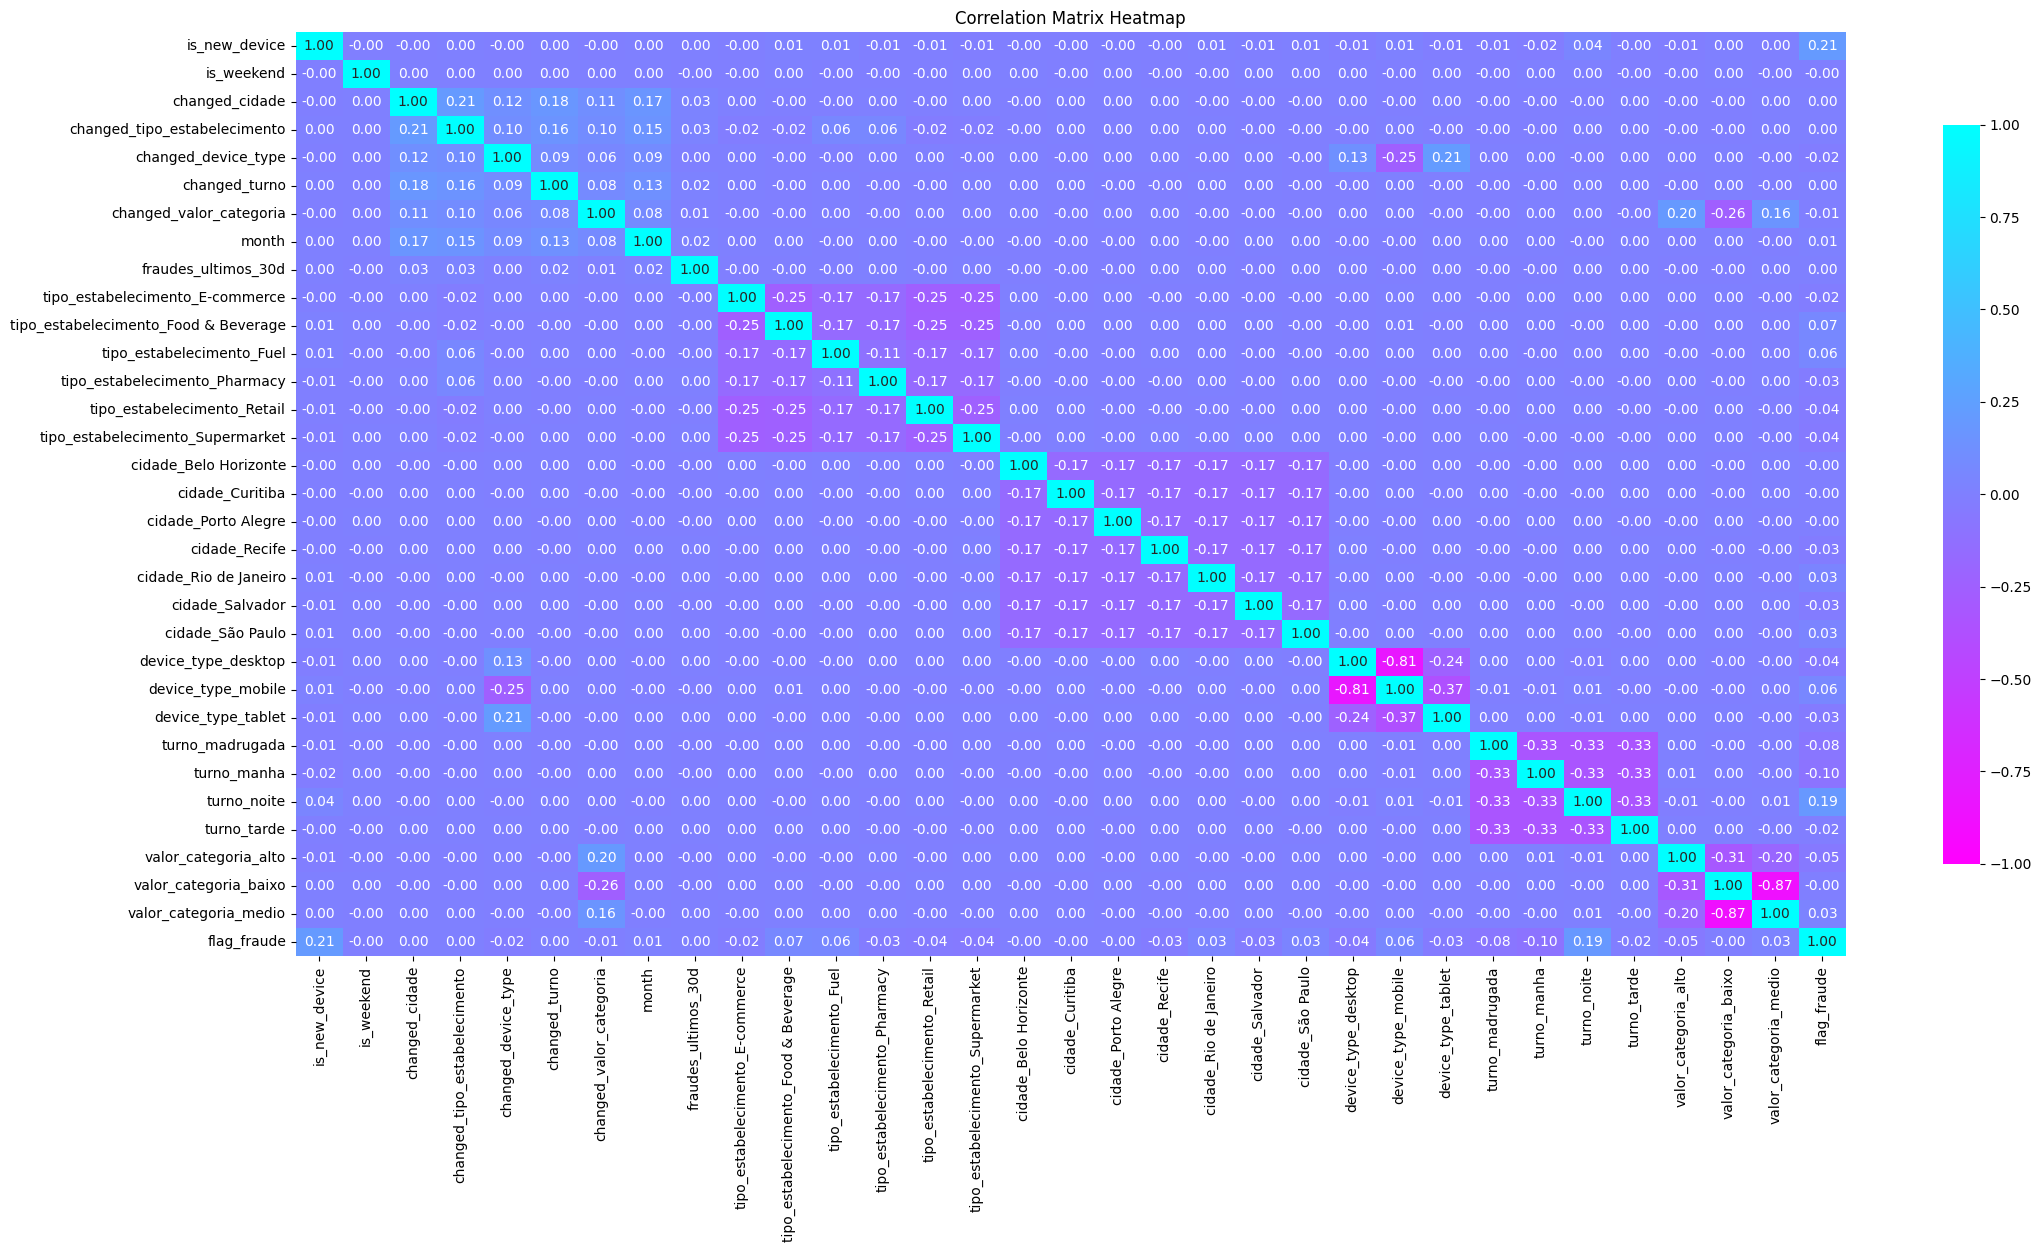

In [24]:
# Correlation studies

# Apply pearson/spearman correlation at final dataset.
# ---------------------------------------------------------
corr_matrix = df_historical.corr(method='pearson')
plt.figure(figsize=(25, 12))
sns.heatmap(corr_matrix, annot=True, cmap='cool_r', vmin=-1, vmax=1, fmt=".2f", cbar_kws={"shrink": 0.8})
plt.title("Correlation Matrix Heatmap")
plt.show()

The correlation matrix shows that most of the data do not correlate with the target feature (flag_fraude). The only exception is the “is_new_device” feature, which had a Pearson correlation of 0.21 and a Spearman correlation of 0.26. This feature does indeed make sense, since fraudulent transactions are typically carried out by third parties on new devices.

In [25]:
# Saving model Features
with open("model_features.txt", "w", encoding="utf-8") as file:
    for feature in df_historical.columns:
        if feature != 'flag_fraude':
            file.write(f"{feature}\n")
        else:
            pass 

The final list of features used for training will be saved to ensure later that the data used to predict new results is correct.

In [26]:
# Separating the dataset for train and test using train_test_split 

X = df_historical.drop('flag_fraude', axis=1)
y = df_historical['flag_fraude']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.08, random_state=21)


print(y_test.value_counts())

flag_fraude
False    40249
True      1633
Name: count, dtype: int64


A small value for `test_size` was chosen because it represents random transactions throughout the entire year of 2025, making it possible to capture all seasonal patterns. In addition, the number of transactions used for testing was similar to the number in the January 2026 dataset.

Calculating the number of “False” and “True” values confirms the imbalance in the dataframe. Therefore, the models under study will use balancing techniques 

## Baseline Model 

Here we will create an baseline model for comparasion purposes using a simple logistic regression with balanced weights.

/Users/leonardocorreia/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/leonardocorreia/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/leonardocorreia/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/leonardocorreia/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/leonardocorreia/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  g

===== Baseline Logistic Regression =====
Threshold: 0.5000
ROC-AUC: 0.8925
PR-AUC:  0.2033
Precision: 0.1355
Recall:    0.8224
F1-score:  0.2326
Classification report:
              precision    recall  f1-score   support

  Não fraude       0.99      0.79      0.88     40249
      Fraude       0.14      0.82      0.23      1633

    accuracy                           0.79     41882
   macro avg       0.56      0.80      0.55     41882
weighted avg       0.96      0.79      0.85     41882



/Users/leonardocorreia/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/leonardocorreia/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/leonardocorreia/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


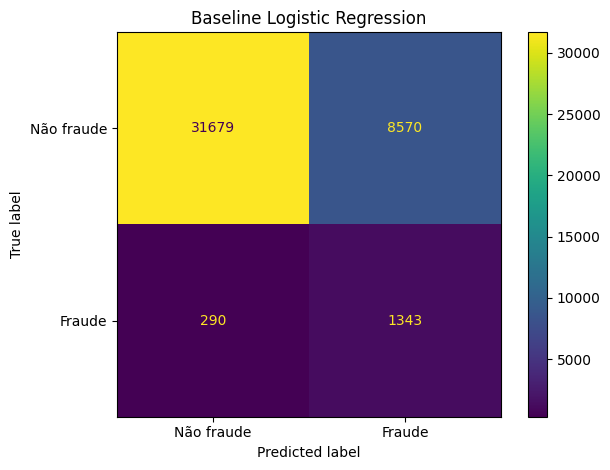

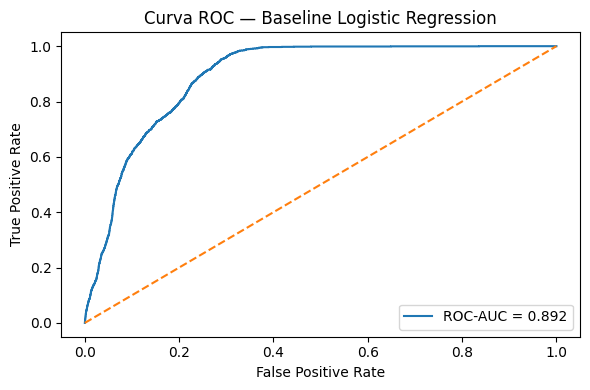

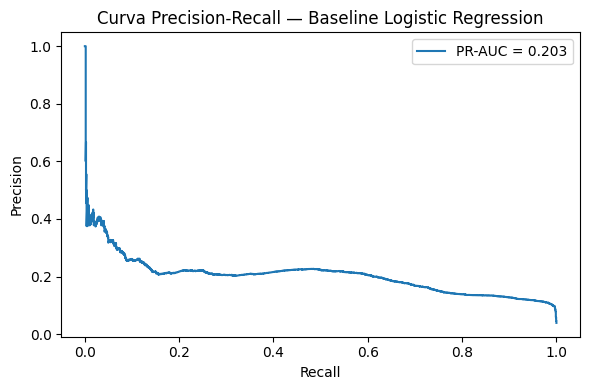

In [31]:
logreg_model = LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        n_jobs=-1,
        random_state= 21
    )

logreg_model.fit(X_train, y_train)
valid_proba_logreg = logreg_model.predict_proba(X_test)[:, 1]

evaluate_proba(y_test, valid_proba_logreg, threshold=0.5, title='Baseline Logistic Regression')
plot_roc_pr_curves(y_test, valid_proba_logreg, title='Baseline Logistic Regression')

## Hist Gradient Boosting Classifier

Under some tests, Hist Gradient Boosting Classifier presented best results when compared with MLP, KNN and Random Forest

===== HistGradientBoosting — threshold 0.5 =====
Threshold: 0.5000
ROC-AUC: 0.9462
PR-AUC:  0.4527
Precision: 0.1564
Recall:    0.9498
F1-score:  0.2685
Classification report:
              precision    recall  f1-score   support

  Não fraude       1.00      0.79      0.88     40249
      Fraude       0.16      0.95      0.27      1633

    accuracy                           0.80     41882
   macro avg       0.58      0.87      0.58     41882
weighted avg       0.96      0.80      0.86     41882



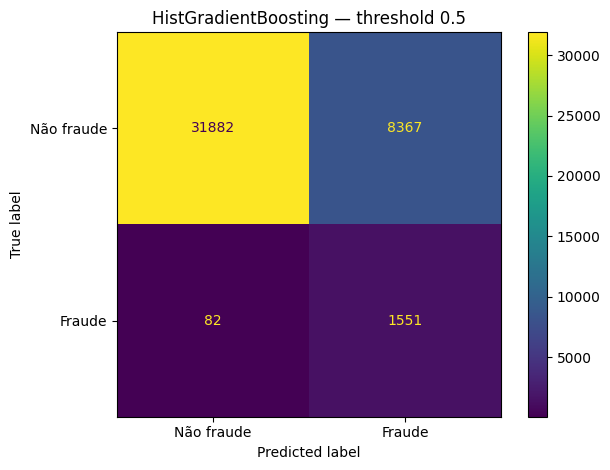

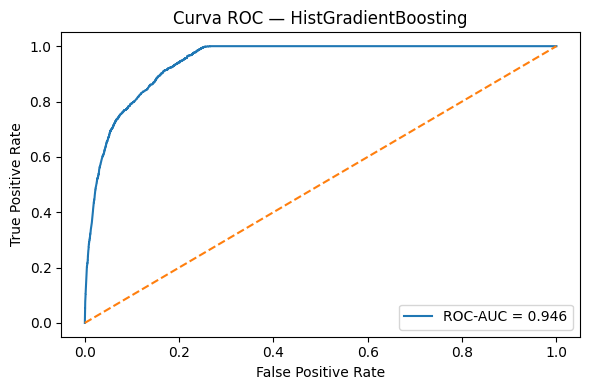

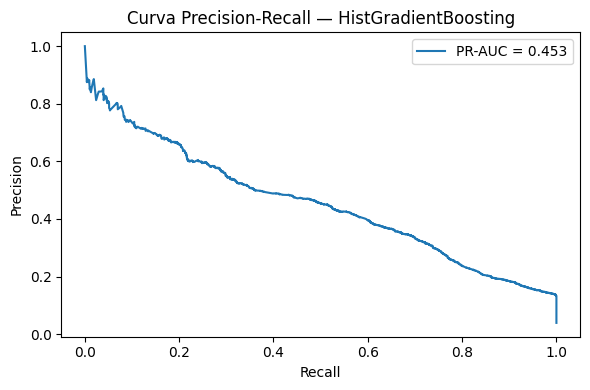

===== HistGradientBoosting — threshold 0.7 =====
Threshold: 0.7000
ROC-AUC: 0.9462
PR-AUC:  0.4527
Precision: 0.3054
Recall:    0.7373
F1-score:  0.4319
Classification report:
              precision    recall  f1-score   support

  Não fraude       0.99      0.93      0.96     40249
      Fraude       0.31      0.74      0.43      1633

    accuracy                           0.92     41882
   macro avg       0.65      0.83      0.70     41882
weighted avg       0.96      0.92      0.94     41882



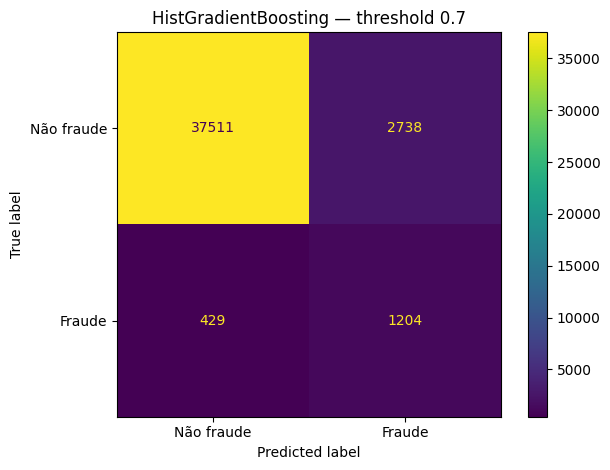

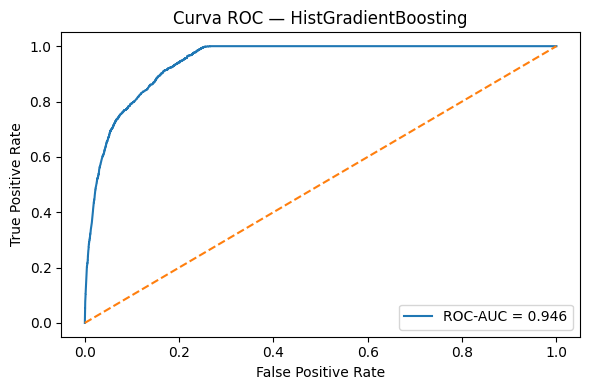

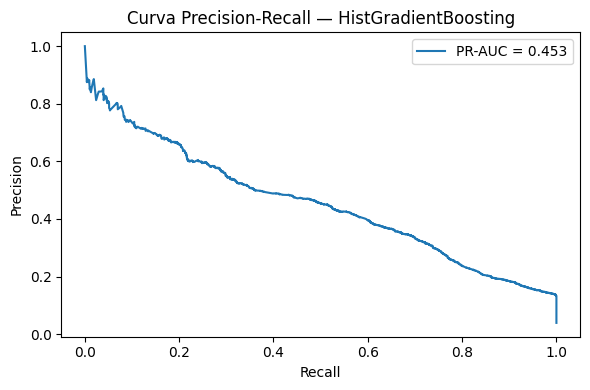

In [32]:
# Create the Hist Gradient Boosting Classifier model
# ---------------------------------------------------------
hgb_model = HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=500,
        max_leaf_nodes=100,
        l2_regularization=0.0001,
        random_state=42)

# Compute balanced sample weights
# ---------------------------------------------------------
sample_weight = compute_sample_weight(
    class_weight='balanced', 
    y=y_train
)

# Train the Random Forest model
# ---------------------------------------------------------
hgb_model.fit(
    X_train, 
    y_train, 
    sample_weight=sample_weight
)

# Predict fraud probabilities
# ---------------------------------------------------------
valid_proba_hgb = hgb_model.predict_proba(X_test)[:, 1]

# Evaluate the model using threshold 0.5
# ---------------------------------------------------------
evaluate_proba(
    y_test, valid_proba_hgb,
    threshold=0.5, 
    title='HistGradientBoosting — threshold 0.5'
)
plot_roc_pr_curves(
    y_test, 
    valid_proba_hgb, 
    title='HistGradientBoosting'
)

# Evaluate the model using threshold 0.7
# ---------------------------------------------------------
evaluate_proba(
    y_test, valid_proba_hgb, 
    threshold=0.7, 
    title='HistGradientBoosting — threshold 0.7'
)
plot_roc_pr_curves(
    y_test, 
    valid_proba_hgb, 
    title='HistGradientBoosting'
)

Following a thorough examination of the two confusion matrices, it has been confirmed that the threshold is critical in determining whether fraud occurred. As this decision is made by the company, the threshold must adhere to the previously established security guidelines. For instance, if it is deemed acceptable to predict a higher number of non-fraudulent transactions as fraudulent, even if this results in the incorrect classification of some fraudulent transactions as non-fraudulent, then a higher threshold would be required. These values are directly related to the precision and recall provided by the model.

## Random Forest

===== Random Forest — threshold 0.5 =====
Threshold: 0.5000
ROC-AUC: 0.8967
PR-AUC:  0.2933
Precision: 0.2640
Recall:    0.3570
F1-score:  0.3036
Classification report:
              precision    recall  f1-score   support

  Não fraude       0.97      0.96      0.97     40249
      Fraude       0.26      0.36      0.30      1633

    accuracy                           0.94     41882
   macro avg       0.62      0.66      0.64     41882
weighted avg       0.95      0.94      0.94     41882



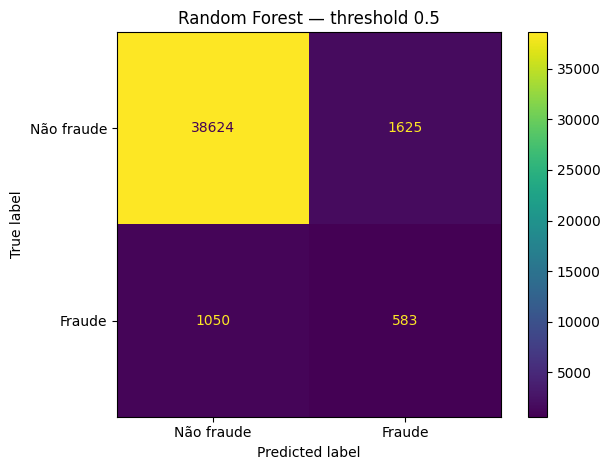

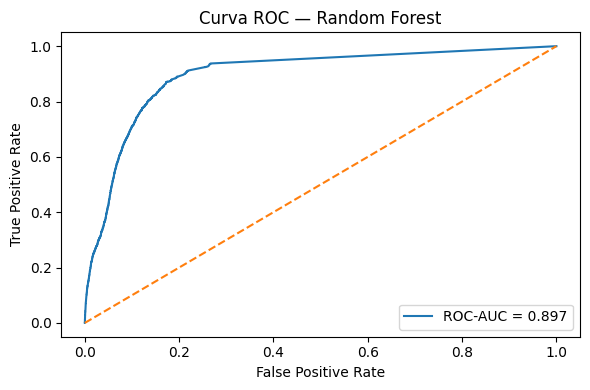

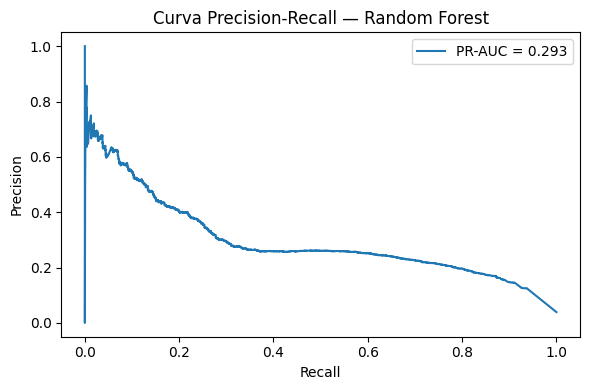

===== Random Forest — threshold 0.7 =====
Threshold: 0.7000
ROC-AUC: 0.8967
PR-AUC:  0.2933
Precision: 0.3988
Recall:    0.2088
F1-score:  0.2741
Classification report:
              precision    recall  f1-score   support

  Não fraude       0.97      0.99      0.98     40249
      Fraude       0.40      0.21      0.27      1633

    accuracy                           0.96     41882
   macro avg       0.68      0.60      0.63     41882
weighted avg       0.95      0.96      0.95     41882



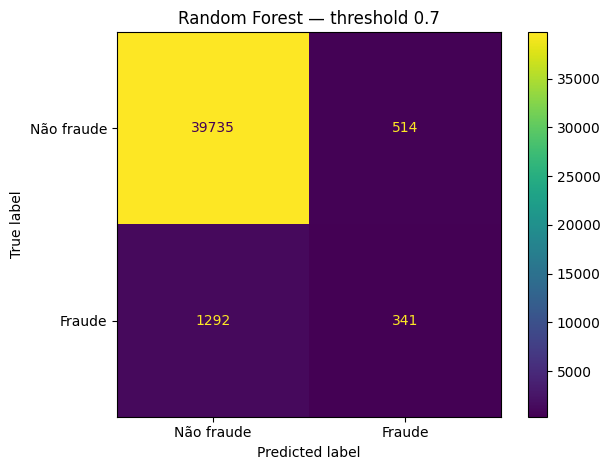

In [ ]:
# Create the Random Forest model
# ---------------------------------------------------------
rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight=None,
    random_state=42,
    n_jobs=-1,
)

# Compute balanced sample weights
# ---------------------------------------------------------
sample_weight = compute_sample_weight(
    class_weight="balanced",
    y=y_train,
)

# Train the Random Forest model
# ---------------------------------------------------------
rf_model.fit(
    X_train,
    y_train,
    sample_weight=sample_weight,
)

# Predict fraud probabilities
# ---------------------------------------------------------
valid_proba_rf = rf_model.predict_proba(X_test)[:, 1]

# Evaluate the model using threshold 0.5
# ---------------------------------------------------------
evaluate_proba(
    y_test,
    valid_proba_rf,
    threshold=0.5,
    title="Random Forest — threshold 0.5",
)

plot_roc_pr_curves(
    y_test,
    valid_proba_rf,
    title="Random Forest",
)

# Evaluate the model using threshold 0.7
# ---------------------------------------------------------
evaluate_proba(
    y_test,
    valid_proba_rf,
    threshold=0.7,
    title="Random Forest — threshold 0.7",
)

The Random Forest model produced test results very similar to those of the baseline. A high number of errors were found in the “fraude” true label. Therefore, this model will be rejected.

## MLP

/Users/leonardocorreia/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/leonardocorreia/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/leonardocorreia/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/leonardocorreia/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/leonardocorreia/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/leonardocorreia/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/leonardocorreia/Library

===== MLPClassifier — threshold 0.2 =====
Threshold: 0.2000
ROC-AUC: 0.9467
PR-AUC:  0.4500
Precision: 0.3752
Recall:    0.6326
F1-score:  0.4710
Classification report:
              precision    recall  f1-score   support

  Não fraude       0.98      0.96      0.97     40249
      Fraude       0.38      0.63      0.47      1633

    accuracy                           0.94     41882
   macro avg       0.68      0.79      0.72     41882
weighted avg       0.96      0.94      0.95     41882



/Users/leonardocorreia/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/leonardocorreia/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/leonardocorreia/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


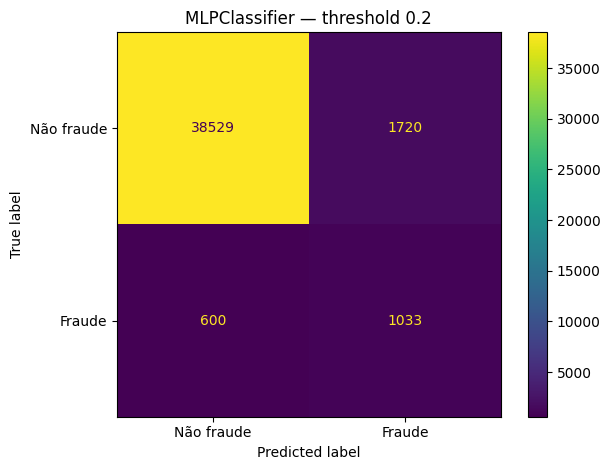

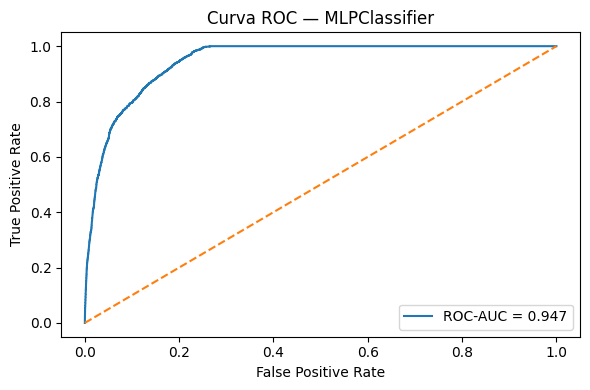

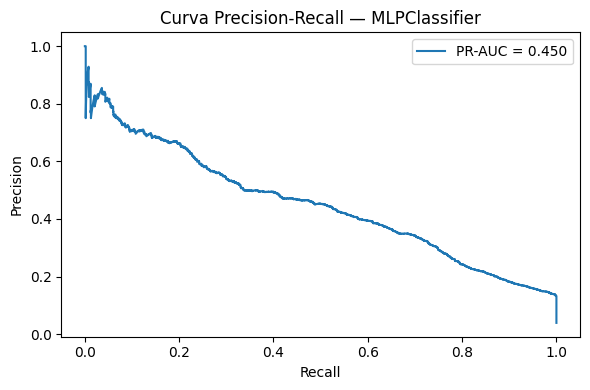

In [33]:
# Create the MLP model
# ---------------------------------------------------------
mlp_model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="logistic",
    solver="adam",
    alpha=0.0001,
    batch_size=256,
    learning_rate="adaptive",
    learning_rate_init=0.001,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.2,
    n_iter_no_change=20,
    random_state=42,
)

# Train the MLP model
# ---------------------------------------------------------
mlp_model.fit(
    X_train,
    y_train,
)

# Predict fraud probabilities
# ---------------------------------------------------------
valid_proba_mlp = mlp_model.predict_proba(X_test)[:, 1]

# Evaluate the model
# ---------------------------------------------------------
evaluate_proba(
    y_test,
    valid_proba_mlp,
    threshold=0.20,
    title="MLPClassifier — threshold 0.2",
)

plot_roc_pr_curves(
    y_test,
    valid_proba_mlp,
    title="MLPClassifier",
)

The MLP model yielded the best PR-AUC and ROC results. However, it is not possible to balance the data by weights (when using the sklearn library’s MLPClassifier as-is), so it is necessary to set the threshold below 0.5 (the value chosen in the test was 0.2) in order to obtain good results. This configuration leads to a recurring issue with the company’s managing team constantly having to reevaluate the threshold. 

Therefore, the model chosen was the `HistGradientBoostingClassifier`

## Evaluating results for January/2026

In [ ]:
# Load the January 2026 and historical datasets
# ---------------------------------------------------------
df_jan26 = pd.read_csv("transacoes_jan2026.csv")
df_historical = pd.read_csv("transacoes_historico_2025.csv")

# Convert transaction timestamps to datetime
# ---------------------------------------------------------
df_jan26["datahora_transacao"] = pd.to_datetime(
    df_jan26["datahora_transacao"],
    errors="coerce",
)

df_historical["datahora_transacao"] = pd.to_datetime(
    df_historical["datahora_transacao"],
    errors="coerce",
)

# Selecting december data from df_historical
# ---------------------------------------------------------
df_dec25 = df_historical.loc[
    (df_historical["datahora_transacao"] >= "2025-12-01")
    & (df_historical["datahora_transacao"] < "2026-01-01")
].copy()


# Merging datasets
# * In everyday tasks this part wont necessary due to constant flux of data. Here we will have flag_fraude so we can create the feature "feaude_ultimos_30D"
# ---------------------------------------------------------
df_complet = pd.concat(
    [df_dec25, df_jan26],
    ignore_index=True
)

# Reseting index of merged dataset
# ---------------------------------------------------------
df_complet = df_complet.sort_values(
    "datahora_transacao"
).reset_index(drop=True)

# Oppening .txt and .pkl dependencies 
# ---------------------------------------------------------
with open("initial_features.txt", "r", encoding="utf-8") as file:
    feature_list = [line.strip() for line in file if line.strip()]

with open("model_features.txt", "r", encoding="utf-8") as file:
    model_feature_list = [line.strip() for line in file if line.strip()]

with open('encoder.pkl', 'rb') as file:
    encoder_model = pickle.load(file)

with open('scaler.pkl', 'rb') as file:
    scaler_model = pickle.load(file)

# IF ONLY THIS NOTEBOOK IS USED THEN RUN THE FOLLOWING INSTEAD:
# feature_list = initial_features
# model_feature_list = model_features

# encoder_model = encoder
# scaler_model = scaler

# Transforming the dataset to correct dtypes
# ---------------------------------------------------------
df_complet = transform_dtypes(df_complet, feature_list, making_predictions = False)

# Creating features fot the new dataset
# ---------------------------------------------------------
df_complet = create_features(df_complet)


In [35]:
# Removing data from december 2025 after creating features
# ---------------------------------------------------------
df_jan26_process = df_complet.loc[
    df_complet["datahora_transacao"] >= "2026-01-01"
].copy()

# Listing categorical_features and numerical_features
# ---------------------------------------------------------
categorical_features = ['tipo_estabelecimento', 'cidade', 'device_type', 'turno', 'valor_categoria']
numerical_features=['month', 'fraudes_ultimos_30d']

# Preprocessing features in df_jan26_process for predictions
# ---------------------------------------------------------
df_jan26_process, _, _ = preprocessing_features(
    dataframe = df_jan26_process, 
    numerical_features = numerical_features, 
    categorical_features = categorical_features,
    scaler = scaler_model, 
    encoder = encoder_model
    )

# Preprocessing features in df_jan26_process for 
# ---------------------------------------------------------
df_jan26_process = removing_colunms_for_model(
    df_jan26_process, 
    model_feature_list, 
    making_predictions = True)

In [36]:
# Threshold values that will be considerated
# ---------------------------------------------------------
threshold_array = np.array([0.6,0.7,0.8,0.9])

# Calculating the number of different predictions by Threshold
# ---------------------------------------------------------
for thr in threshold_array:
    print("Prediction results for threshold = ", thr)

    valid_proba_hgb = hgb_model.predict_proba(df_jan26_process)[:, 1]

    pred_fraud = np.where(valid_proba_hgb >= thr, 1, 0)

    count = np.bincount(pred_fraud)

    print(f"Number of 0s: {count[0]}")
    print(f"Number of 1s: {count[1]}")

Prediction results for threshold =  0.6
Number of 0s: 36968
Number of 1s: 7483
Prediction results for threshold =  0.7
Number of 0s: 40648
Number of 1s: 3803
Prediction results for threshold =  0.8
Number of 0s: 41083
Number of 1s: 3368
Prediction results for threshold =  0.9
Number of 0s: 42628
Number of 1s: 1823


Based on these results, the management team can more easily identify the threshold value they want. A lower threshold offers a safer approach, while a higher threshold provides greater accuracy.

In [37]:
# When using a threshold of 0.9, the predictions for January 2026 are close to those for January 2025 (about 1,700 fraudulent transactions).

# Load AGAIN the January 2026 dataset
# ---------------------------------------------------------
df_jan26 = pd.read_csv("transacoes_jan2026.csv")


# Saving new dataset of Jan/2026 with the predictions
# ---------------------------------------------------------
valid_proba_hgb = hgb_model.predict_proba(df_jan26_process)[:, 1]
pred_fraud = np.where(valid_proba_hgb >= 0.9, 1, 0)

df_jan26["fraud_probability"] = valid_proba_hgb
df_jan26["fraud_prediction"] = pred_fraud

df_jan26_with_prediction = df_jan26

df_jan26_with_prediction.to_csv('transacoes_jan2026_predictions.csv')

In [ ]:
df_jan26_with_prediction

,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,valor_transacao,nome_cliente,cidade,device_type,is_new_device,temperatura_celsius,codigo_postal,score_interno,turno,valor_categoria,cidade_regiao,fraud_probability,fraud_prediction
0,2026-01-01 00:00:00,Pharmacy Z,Pharmacy,21.72,Cliente_16241,Curitiba,desktop,False,17.4,36135-417,691,madrugada,baixo,Sul,0.000946,0
1,2026-01-01 00:01:00,Electronics Store,Retail,28.70,Cliente_10027,Porto Alegre,mobile,False,11.9,83134-620,292,madrugada,baixo,Sul,0.001413,0
2,2026-01-01 00:02:00,Restaurant X,Food & Beverage,34.55,Cliente_13606,Porto Alegre,desktop,False,15.0,41309-759,81,madrugada,medio,Sul,0.002203,0
3,2026-01-01 00:03:00,Gas Station,Fuel,57.53,Cliente_7302,Belo Horizonte,desktop,False,23.5,15793-404,54,madrugada,medio,Sudeste,0.005022,0
4,2026-01-01 00:04:00,Gas Station,Fuel,149.50,Cliente_20061,Recife,desktop,False,28.1,73917-730,31,madrugada,alto,Nordeste,0.001842,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44446,2026-01-31 23:54:00,Restaurant Y,Food & Beverage,19.11,Cliente_16111,Porto Alegre,mobile,False,13.8,96526-910,342,noite,baixo,Sul,0.647110,0
44447,2026-01-31 23:55:00,Supermarket A,Supermarket,8.55,Cliente_8637,Belo Horizonte,desktop,False,18.0,47720-661,525,noite,baixo,Sudeste,0.491127,0
44448,2026-01-31 23:56:00,Clothing Store,Retail,19.29,Cliente_25552,Recife,tablet,False,35.6,44682-945,712,noite,baixo,Nordeste,0.586910,0
44449,2026-01-31 23:57:00,Online Shop 2,E-commerce,6.10,Cliente_9121,Recife,mobile,False,32.4,64626-916,849,noite,baixo,Nordeste,0.647897,0
